# Subject-level leakage in Parkinson's voice classification

**Ashfaq Hussain Mohammad** · walkthrough of the corrected analysis

This notebook is a guided tour. It does **not** re-run the full analysis — that takes about
35 minutes and lives in `src/*.py`. Instead it:

1. shows the structure of the data that causes the problem,
2. **demonstrates the leak live**, in a few seconds,
3. runs one small live comparison so you can watch it happen,
4. loads the full precomputed results and figures.

Every number shown here was produced by the scripts in `src/` and is stored in
`results/tables/`. Nothing in this notebook is typed in by hand.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")

# Find the project root by walking up until src/config.py appears,
# so this works wherever the notebook is opened from.
root = next((d for d in [Path.cwd(), *Path.cwd().parents]
             if (d / "src" / "config.py").exists()), None)
if root is None:
    raise RuntimeError("Could not find project root (looked for src/config.py)")
sys.path.insert(0, str(root / "src"))

import numpy as np, pandas as pd
import config as C

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)
print("project root:", root)

project root: /Users/ashfaq/Documents/07. THESIS/Project


---
## 1. The data, and why its shape matters

The key fact is not how many recordings there are. It is **how many people** they came from.

In [2]:
uci   = pd.read_csv(C.UCI_OUT)
sakar = pd.read_csv(C.SAKAR_TRAIN_OUT)

summary = pd.DataFrame([
    {"dataset": "UCI / MDVP", "recordings": len(uci),
     "people": uci.subject.nunique(),
     "recordings per person": round(len(uci) / uci.subject.nunique(), 1),
     "sick people": int((uci.groupby('subject').label.first() == 1).sum()),
     "healthy people": int((uci.groupby('subject').label.first() == 0).sum())},
    {"dataset": "Sakar", "recordings": len(sakar),
     "people": sakar.subject.nunique(),
     "recordings per person": round(len(sakar) / sakar.subject.nunique(), 1),
     "sick people": int((sakar.groupby('subject').label.first() == 1).sum()),
     "healthy people": int((sakar.groupby('subject').label.first() == 0).sum())},
])
summary

,dataset,recordings,people,recordings per person,sick people,healthy people
0,UCI / MDVP,195,32,6.1,24,8
1,Sakar,1040,40,26.0,20,20


In [3]:
# One person's recordings in the UCI set -- all six belong to the same speaker.
uci[uci.subject == "phon_R01_S01"][["name", "subject", "label",
                                    "MDVP:Fo(Hz)", "MDVP:Jitter(%)", "HNR"]]

,name,subject,label,MDVP:Fo(Hz),MDVP:Jitter(%),HNR
0,phon_R01_S01_1,phon_R01_S01,1,119.992,0.00784,21.033
1,phon_R01_S01_2,phon_R01_S01,1,122.400,0.00968,19.085
2,phon_R01_S01_3,phon_R01_S01,1,116.682,0.01050,20.651
3,phon_R01_S01_4,phon_R01_S01,1,116.676,0.00997,20.644
4,phon_R01_S01_5,phon_R01_S01,1,116.014,0.01284,19.649
5,phon_R01_S01_6,phon_R01_S01,1,120.552,0.00968,21.378


Six rows, one person. Shuffle all 195 rows into a training and a test pile and five of this
person's recordings land in training while the sixth lands in testing.

The model does not have to learn anything about Parkinson's. It only has to recognise the voice.

---
## 2. Demonstrating the leak

This is the core claim, and it is measurable rather than rhetorical.

For each way of splitting the data, we ask: **what fraction of the test recordings come from a
person the model already heard during training?**

In [4]:
from cv_core import outer_splits

rows = []
for name, df, feats in [("UCI / MDVP", uci, C.UCI_FEATURES), ("Sakar", sakar, C.SAKAR_FEATURES)]:
    X, y, g = df[feats].values, df.label.values, df.subject.values
    for regime, label in [("A_leaky_recording", "split by RECORDING (old way)"),
                          ("B_group_kfold",     "split by PERSON (correct way)")]:
        shared = [np.mean([s in set(g[tr]) for s in g[te]])
                  for tr, te in outer_splits(regime, X, y, g, 5, C.SEED)]
        rows.append({"dataset": name, "how we split": label,
                     "test recordings whose speaker was in training":
                        f"{np.mean(shared) * 100:.0f}%"})

pd.DataFrame(rows)

,dataset,how we split,test recordings whose speaker was in training
0,UCI / MDVP,split by RECORDING (old way),100%
1,UCI / MDVP,split by PERSON (correct way),0%
2,Sakar,split by RECORDING (old way),100%
3,Sakar,split by PERSON (correct way),0%


**100% versus 0%.**

Under the old way, *every single* test recording came from someone the model had already heard.
Not most of them — all of them. Under the correct way, none did.

That is the entire problem, in one table.

---
## 3. Watching it happen, live

Now we actually train models both ways and compare. This runs for real — roughly half a minute.

To keep it quick this uses one dataset and fixed settings. The full version in
`src/run_cv_comparison.py` tunes every model inside every fold, across both datasets and three
splitting methods.

In [5]:
from sklearn.model_selection import cross_val_score, StratifiedKFold, StratifiedGroupKFold
from models import get_fixed_models

X, y, g = uci[C.UCI_FEATURES].values, uci.label.values, uci.subject.values

results = []
for model_name in ["Logistic Regression", "XGBoost"]:
    by_recording = cross_val_score(
        get_fixed_models()[model_name], X, y,
        cv=StratifiedKFold(5, shuffle=True, random_state=C.SEED)).mean()
    by_person = cross_val_score(
        get_fixed_models()[model_name], X, y, groups=g,
        cv=StratifiedGroupKFold(5, shuffle=True, random_state=C.SEED)).mean()
    results.append({"model": model_name,
                    "split by recording": round(by_recording, 3),
                    "split by person": round(by_person, 3),
                    "drop": round(by_recording - by_person, 3)})

live = pd.DataFrame(results)
print("Always guessing 'sick' on this dataset already scores 0.754\n")
live

Always guessing 'sick' on this dataset already scores 0.754



,model,split by recording,split by person,drop
0,Logistic Regression,0.841,0.777,0.064
1,XGBoost,0.918,0.758,0.160


Two things to notice.

**Both models get worse** once the split respects the person.

**The complicated model falls further.** XGBoost has more capacity to memorise individual
voices, so it gains more from the leak — and loses more when the leak is removed.

*These exact figures will differ slightly from the table in section 4.* This cell uses one
random split and fixed settings; the table averages ten splits and tunes each model inside
every fold. The size of the drop moves a little, the direction never does.

---
## 4. The full results

Everything below was computed by the scripts in `src/` and read from disk. The headline numbers
average over ten different random splits, because with only 32 people a single split is a lucky
draw rather than a measurement.

In [6]:
seeds = pd.read_csv(C.TABLES / "seed_sensitivity_summary.csv")
headline = seeds[["dataset", "model", "A_mean", "B_mean",
                  "inflation_mean", "inflation_ci_lo", "inflation_ci_hi"]].copy()
headline.columns = ["dataset", "model", "split by recording", "split by person",
                    "inflation", "95% CI low", "95% CI high"]
headline.round(3)

,dataset,model,split by recording,split by person,inflation,95% CI low,95% CI high
0,UCI/MDVP,Logistic Regression,0.849,0.785,0.065,0.037,0.092
1,UCI/MDVP,KNN,0.912,0.756,0.155,0.139,0.172
2,UCI/MDVP,Decision Tree,0.856,0.743,0.114,0.067,0.161
3,UCI/MDVP,Gradient Boosting,0.916,0.787,0.129,0.109,0.149
4,UCI/MDVP,XGBoost,0.917,0.786,0.131,0.103,0.158
5,Sakar,Logistic Regression,0.630,0.572,0.058,0.043,0.072
6,Sakar,KNN,0.670,0.559,0.110,0.094,0.127
7,Sakar,Decision Tree,0.621,0.534,0.087,0.060,0.115
8,Sakar,Gradient Boosting,0.688,0.558,0.130,0.116,0.144
9,Sakar,XGBoost,0.697,0.555,0.143,0.128,0.158


Accuracy falls by **5.8 to 15.5 points**, on two independent datasets, with everything except the
splitting rule held fixed.

The simple model (logistic regression) loses the least on both. The tree ensembles lose roughly
double.

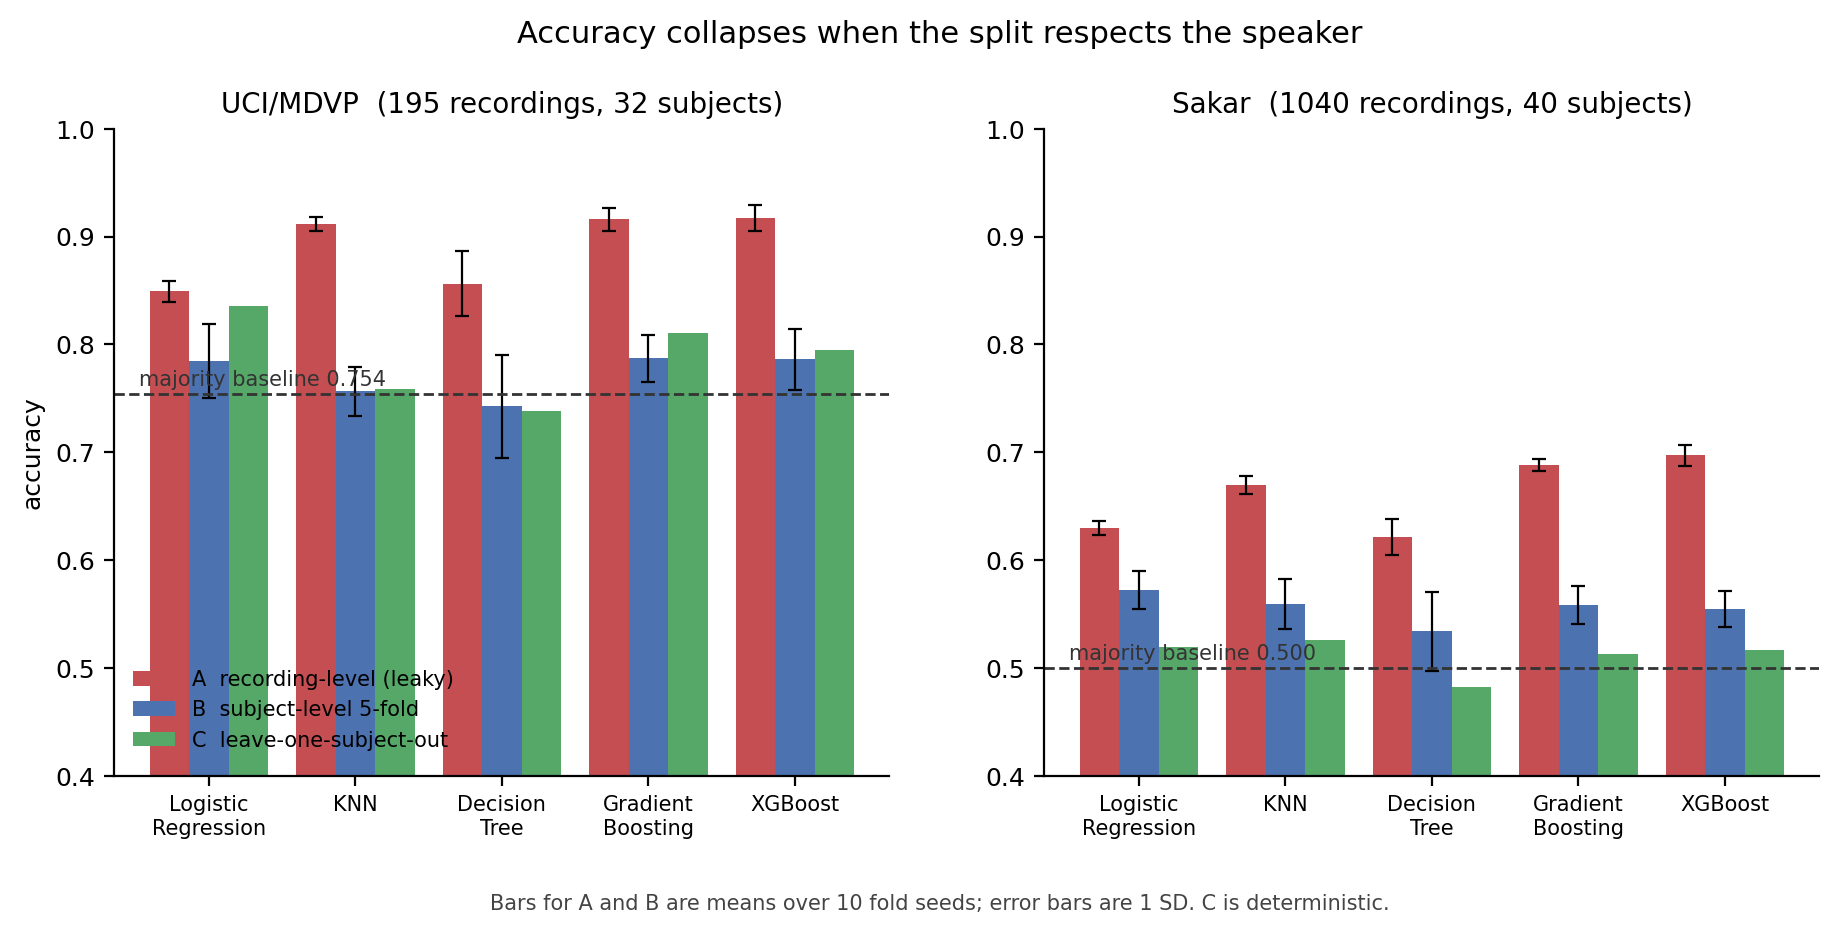

In [7]:
from IPython.display import Image, display
display(Image(filename=str(C.FIGURES / "fig2_accuracy_by_regime.png")))

The dashed line is what you score by always answering "sick". On the left dataset that is 0.754.

Under the correct split, most models barely clear it — and the decision tree falls **below** it.

---
## 5. What accuracy hides

Accuracy looks survivable. The breakdown by group does not.

In [8]:
hc = seeds[["dataset", "model", "recall_hc_A_mean", "recall_hc_B_mean"]].copy()
hc.columns = ["dataset", "model", "healthy correct (by recording)", "healthy correct (by person)"]
hc["healthy people wrongly called sick"] = (
    1 - hc["healthy correct (by person)"]).map("{:.0%}".format)
hc.round(3)

,dataset,model,healthy correct (by recording),healthy correct (by person),healthy people wrongly called sick
0,UCI/MDVP,Logistic Regression,0.583,0.290,71%
1,UCI/MDVP,KNN,0.804,0.285,71%
2,UCI/MDVP,Decision Tree,0.698,0.365,64%
3,UCI/MDVP,Gradient Boosting,0.783,0.392,61%
4,UCI/MDVP,XGBoost,0.763,0.390,61%
5,Sakar,Logistic Regression,0.623,0.558,44%
6,Sakar,KNN,0.625,0.556,44%
7,Sakar,Decision Tree,0.615,0.551,45%
8,Sakar,Gradient Boosting,0.666,0.578,42%
9,Sakar,XGBoost,0.685,0.581,42%


On the UCI dataset, under honest validation, the models label **61% to 72% of healthy people as
having Parkinson's disease**.

A screening tool with that false-alarm rate is not usable in a clinic. The accuracy column never
shows you this.

---
## 6. The obvious objection, answered in advance

*"You mixed different speaking tasks together. Sustained vowels are the standard clinical test —
did you try those on their own?"*

Yes. The second dataset has four task types. Here is each one, evaluated separately.

In [9]:
rt = pd.read_csv(C.TABLES / "recording_type.csv")
rt = rt[rt.regime == "B_group_kfold"]
table = rt.pivot_table(index="model", columns="rec_type", values="accuracy_mean")
table = table[["vowel", "number", "sentence", "word"]].round(3)
print("Pure guessing scores 0.500\n")
print(f"Best result anywhere: {table.max().max():.3f}\n")
table

Pure guessing scores 0.500

Best result anywhere: 0.596



rec_type,vowel,number,sentence,word
model,,,,
Decision Tree,0.480,0.516,0.548,0.507
Gradient Boosting,0.527,0.546,0.566,0.517
KNN,0.446,0.596,0.514,0.519
Logistic Regression,0.577,0.595,0.585,0.541
XGBoost,0.509,0.546,0.571,0.510


Nothing reaches 0.60. And sustained vowels — the standard clinical elicitation — are the
**weakest** task for four of the five models.

No speaking task rescues the result.

---
## 7. Summary

| | |
|---|---|
| Accuracy lost when splitting correctly | **5.8 – 15.5 points**, both datasets |
| Test recordings sharing a speaker with training, old method | **100%** |
| Healthy people wrongly called sick, corrected method | **61 – 72%** |
| Best result across all speaking tasks | **0.596** (guessing = 0.500) |
| Accuracy on 28 unseen patients | **0.41 – 0.59** |
| Voice measurements that hold up statistically | **none** |

The published ranking also reverses. Under the old method the simple model ranked last of five;
under the strictest correct method it ranks first.

This does not prove voice carries no signal. It shows these two datasets, at 32 and 40 people,
cannot support the claims built on them.

---

**Reproducing everything:** `README.md` lists the ten commands. A clean clone rebuilds the
processed data byte-for-byte, and `src/verify_manuscript.py` checks all 144 numbers in the paper
against these tables.